# Benchart AI — Jupyter Engineering & Data Science Lab

A notebook-first workspace for benchmark analytics, Python data science, machine learning, computer vision checks, and preliminary mechanical-engineering calculations.

**Included visual outputs:** benchmark comparisons, beam shear-force/bending-moment diagrams, interactive 3D surfaces/scatter, CFD velocity fields, FEA exported-result stress clouds, and a project timetable.

> Scope note: FEA and CFD sections post-process supplied/exported results; they do not solve the full governing equations. Example datasets and 3D concept plots are illustrative. Engineering calculations are educational/preliminary and require independent verification before design use.

## 1. Environment setup

In [1]:
# Run once in a fresh environment if required:
# %pip install -r ../requirements.txt
# %pip install plotly jupyter ipykernel

In [2]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path.cwd()
# Make imports work whether the notebook is opened from notebooks/ or project root.
candidates = [PROJECT_ROOT, PROJECT_ROOT.parent, PROJECT_ROOT.parent.parent]
for candidate in candidates:
    if (candidate / "benchart_ai").is_dir():
        sys.path.insert(0, str(candidate))
        break

from benchart_ai.cleaning import clean_benchmark_frame
from benchart_ai.statistics import summarize, compare_groups
from benchart_ai.ml import detect_anomalies
from benchart_ai.beam import analyze_simply_supported_beam
from benchart_ai.cfd import analyze_velocity_field
from benchart_ai.fea import analyze_fea
from benchart_ai.engineering_tools import (
    MATERIALS, unit_convert, shaft_torsion, goodman_check,
    factorial_design, correlation_matrix
)
from benchart_ai.model_training import train_tabular_model

try:
    import plotly.express as px
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False
    print("Plotly not installed; static Matplotlib charts remain available.")

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Benchart AI notebook environment ready.")

Benchart AI notebook environment ready.


## 2. Load and clean benchmark data

In [3]:
# Replace this sample with pd.read_csv('your_benchmarks.csv') when ready.
raw = pd.DataFrame([
    {"name":"Matrix multiply","value":120,"unit":"ms","group":"Device A","run":1},
    {"name":"Matrix multiply","value":118,"unit":"ms","group":"Device A","run":2},
    {"name":"Matrix multiply","value":125,"unit":"ms","group":"Device A","run":3},
    {"name":"Matrix multiply","value":98,"unit":"ms","group":"Device B","run":1},
    {"name":"Matrix multiply","value":101,"unit":"ms","group":"Device B","run":2},
    {"name":"Matrix multiply","value":96,"unit":"ms","group":"Device B","run":3},
    {"name":"Image resize","value":42,"unit":"ms","group":"Device A","run":1},
    {"name":"Image resize","value":44,"unit":"ms","group":"Device A","run":2},
    {"name":"Image resize","value":39,"unit":"ms","group":"Device A","run":3},
    {"name":"Image resize","value":33,"unit":"ms","group":"Device B","run":1},
    {"name":"Image resize","value":31,"unit":"ms","group":"Device B","run":2},
    {"name":"Image resize","value":32,"unit":"ms","group":"Device B","run":3},
])
bench = clean_benchmark_frame(raw)
display(bench)
print("Rows after cleaning:", len(bench), "of", len(raw))

,name,value,unit,group,run
0,Matrix multiply,120,ms,Device A,1
1,Matrix multiply,118,ms,Device A,2
2,Matrix multiply,125,ms,Device A,3
3,Matrix multiply,98,ms,Device B,1
4,Matrix multiply,101,ms,Device B,2
5,Matrix multiply,96,ms,Device B,3
6,Image resize,42,ms,Device A,1
7,Image resize,44,ms,Device A,2
8,Image resize,39,ms,Device A,3
9,Image resize,33,ms,Device B,1


Rows after cleaning: 12 of 12


## 3. Descriptive statistics and comparison

In [4]:
summary = summarize(bench)
display(pd.DataFrame(summary["benchmarks"]))
comparison = pd.DataFrame(compare_groups(bench, "Device A", "Device B"))
display(comparison)

,group,name,unit,count,mean,median,std,min,max,p90,p95,p99
0,Device A,Image resize,ms,3,41.666667,42.0,2.516611,39.0,44.0,43.6,43.8,43.96
1,Device A,Matrix multiply,ms,3,121.000000,120.0,3.605551,118.0,125.0,124.0,124.5,124.90
2,Device B,Image resize,ms,3,32.000000,32.0,1.000000,31.0,33.0,32.8,32.9,32.98
3,Device B,Matrix multiply,ms,3,98.333333,98.0,2.516611,96.0,101.0,100.4,100.7,100.94


,name,unit,baseline,candidate,delta,change_percent,status
0,Image resize,ms,41.666667,32.000000,-9.666667,-23.200000,better
1,Matrix multiply,ms,121.000000,98.333333,-22.666667,-18.732782,better


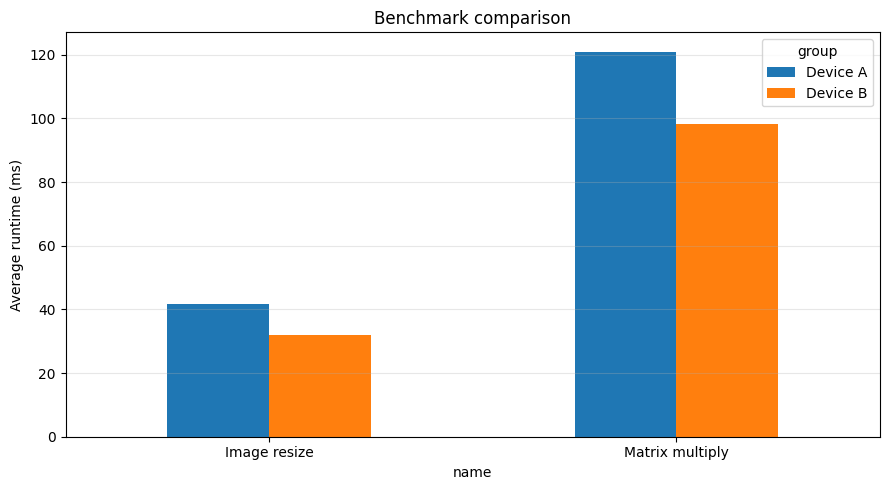

In [5]:
pivot = bench.pivot_table(index="name", columns="group", values="value", aggfunc="mean")
ax = pivot.plot(kind="bar", figsize=(9,5), rot=0)
ax.set_title("Benchmark comparison"); ax.set_ylabel("Average runtime (ms)"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"benchmark_comparison.png", dpi=150); plt.show()

## 4. Data cleaning, distributions and anomaly detection

count        mean       std  ...    50%    75%    max
name            group                                  ...                     
Image resize    Device A    3.0   41.666667  2.516611  ...   42.0   43.0   44.0
                Device B    3.0   32.000000  1.000000  ...   32.0   32.5   33.0
Matrix multiply Device A    3.0  121.000000  3.605551  ...  120.0  122.5  125.0
                Device B    3.0   98.333333  2.516611  ...   98.0   99.5  101.0

[4 rows x 8 columns]

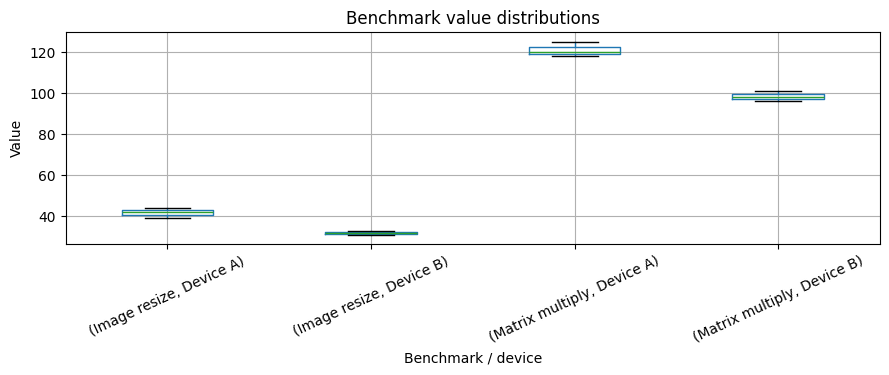

,name,group,run,value,anomaly,anomaly_score
0,Image resize,Device A,1,42,False,0.0
1,Image resize,Device A,2,44,False,0.0
2,Image resize,Device A,3,39,False,0.0
3,Matrix multiply,Device A,1,120,False,0.0
4,Matrix multiply,Device A,2,118,False,0.0
5,Matrix multiply,Device A,3,125,False,0.0
6,Image resize,Device B,1,33,False,0.0
7,Image resize,Device B,2,31,False,0.0
8,Image resize,Device B,3,32,False,0.0
9,Matrix multiply,Device B,1,98,False,0.0


In [6]:
display(bench.groupby(["name","group"])["value"].describe())
fig, ax = plt.subplots(figsize=(9,4))
bench.boxplot(column="value", by=["name","group"], ax=ax, rot=25)
ax.set_title("Benchmark value distributions"); ax.set_xlabel("Benchmark / device"); ax.set_ylabel("Value")
plt.suptitle(""); plt.tight_layout(); plt.show()

anomaly_frame = detect_anomalies(bench, contamination=0.10)
display(anomaly_frame[["name","group","run","value","anomaly","anomaly_score"]])

## 5. Machine learning — tabular regression example

In [7]:
# Synthetic engineering dataset: estimate deflection from load, span and stiffness.
rng = np.random.default_rng(42)
n = 160
ml_data = pd.DataFrame({
    "load_n": rng.uniform(100, 1500, n),
    "span_m": rng.uniform(1.0, 5.0, n),
    "youngs_modulus_gpa": rng.uniform(60, 210, n),
    "inertia_m4": rng.uniform(1e-6, 12e-6, n),
})
ml_data["deflection_mm"] = (
    5 * ml_data.load_n * ml_data.span_m**3 /
    (384 * ml_data.youngs_modulus_gpa * 1e9 * ml_data.inertia_m4) * 1000
)
ml_rows = ml_data.to_dict(orient="records")
ml_result = train_tabular_model(ml_rows, target="deflection_mm", task="regression")
display(ml_result)

{'task': 'regression',
 'target': 'deflection_mm',
 'rows_used': 160,
 'train_rows': 120,
 'test_rows': 40,
 'features': ['load_n', 'span_m', 'youngs_modulus_gpa', 'inertia_m4'],
 'metrics': {'mae': 0.28090965045494537,
  'rmse': 0.5257678209445242,
  'r2': 0.8238542912927935},
 'model': 'RandomForest',
 'note': 'Model is trained in-memory for this request; it is not persisted to disk.'}

## 6. Beam Lab — SFD, BMD and deflection estimate

{'model': 'simply_supported_euler_bernoulli_beam',
 'load_type': 'udl',
 'span_m': 6.0,
 'left_reaction_n': 6000.0,
 'right_reaction_n': 6000.0,
 'max_bending_moment_nm': 9000.0,
 'max_deflection_m': 0.02109375,
 'assumptions': ['linear elastic Euler-Bernoulli beam',
  'simply supported ends',
  'point load at midspan or full-span UDL',
  'small deflection']}

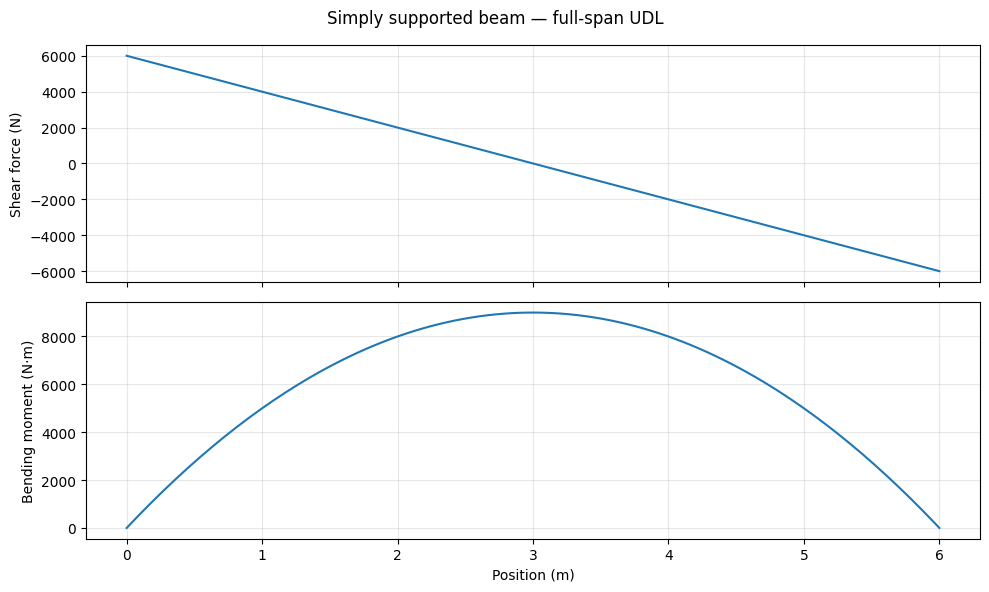

In [8]:
beam_result = analyze_simply_supported_beam(
    span_m=6.0, load_type="udl", load_value=2000.0, points=201,
    elastic_modulus_gpa=200.0, second_moment_m4=8e-6
)
beam_df = pd.DataFrame(beam_result["diagram"])
display({k:v for k,v in beam_result.items() if k != "diagram"})
fig, axes = plt.subplots(2, 1, figsize=(10,6), sharex=True)
axes[0].plot(beam_df.x_m, beam_df.shear_n); axes[0].set_ylabel("Shear force (N)"); axes[0].grid(alpha=.3)
axes[1].plot(beam_df.x_m, beam_df.moment_nm); axes[1].set_ylabel("Bending moment (N·m)"); axes[1].set_xlabel("Position (m)"); axes[1].grid(alpha=.3)
fig.suptitle("Simply supported beam — full-span UDL"); plt.tight_layout()
plt.savefig(OUTPUT_DIR/"beam_sfd_bmd.png", dpi=160); plt.show()

## 7. Interactive 3D visualizations

In [9]:
# 3D response surface (illustrative mathematical surface, not solver output).
x = np.linspace(-3, 3, 55); y = np.linspace(-3, 3, 55)
X, Y = np.meshgrid(x, y); Z = np.sin(np.sqrt(X**2 + Y**2))
if PLOTLY_AVAILABLE:
    fig = go.Figure(data=[go.Surface(x=x, y=y, z=Z, colorscale="Viridis")])
    fig.update_layout(title="3D response surface", scene=dict(xaxis_title="Factor X", yaxis_title="Factor Y", zaxis_title="Response"))
    fig.show()
else:
    fig = plt.figure(figsize=(8,5)); ax=fig.add_subplot(111, projection="3d"); ax.plot_surface(X,Y,Z,cmap="viridis")
    plt.show()

In [10]:
# 3D scatter with three dimensions from the synthetic ML dataset.
if PLOTLY_AVAILABLE:
    fig = px.scatter_3d(ml_data, x="load_n", y="span_m", z="deflection_mm", color="youngs_modulus_gpa",
                        title="3D engineering dataset — load / span / deflection")
    fig.show()
else:
    fig = plt.figure(figsize=(8,5)); ax=fig.add_subplot(111, projection="3d")
    ax.scatter(ml_data.load_n, ml_data.span_m, ml_data.deflection_mm, c=ml_data.youngs_modulus_gpa)
    plt.show()

## 8. CFD exported velocity-field post-processing

{'sample_count': 216,
 'mean_speed': 0.6383357370704649,
 'max_speed': 1.011532914797823,
 'min_speed': 2.4492935982947065e-17,
 'rms_speed': 0.7125618471465118,
 'scope': 'CFD exported-field post-processing only; does not solve Navier-Stokes equations'}

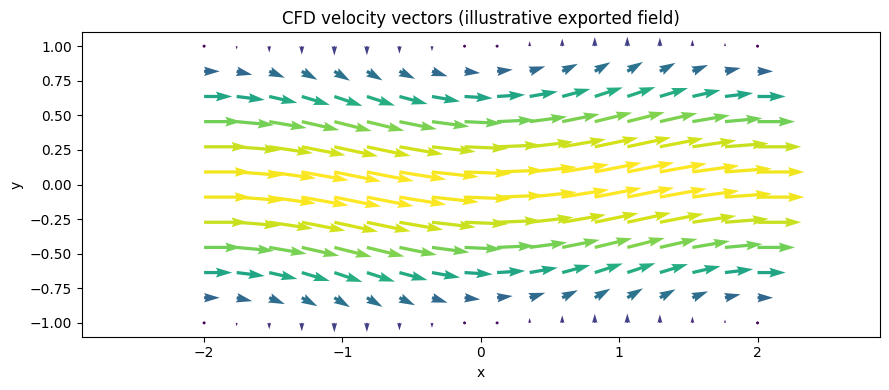

In [11]:
gx, gy = np.meshgrid(np.linspace(-2,2,18), np.linspace(-1,1,12))
u = 1 - gy**2
v = 0.2*np.sin(np.pi*gx/2)
cfd_rows = [{"x":float(a),"y":float(b),"u":float(c),"v":float(d)} for a,b,c,d in zip(gx.ravel(),gy.ravel(),u.ravel(),v.ravel())]
cfd_result = analyze_velocity_field(cfd_rows)
display({k:v for k,v in cfd_result.items() if k != "vectors"})
speed = np.hypot(u,v)
plt.figure(figsize=(9,4)); plt.quiver(gx,gy,u,v,speed); plt.title("CFD velocity vectors (illustrative exported field)")
plt.xlabel("x"); plt.ylabel("y"); plt.axis("equal"); plt.tight_layout(); plt.show()

## 9. FEA exported nodal-results post-processing

In [12]:
rng = np.random.default_rng(9)
fea_rows = []
for node in range(1,151):
    x,y,z = rng.uniform(-1,1,3)
    vm = 80 + 260*np.exp(-((x-.55)**2+(y-.35)**2)*5) + rng.uniform(0,15)
    disp = abs(x)*0.08 + abs(y)*0.03
    fea_rows.append({"node_id":node,"x":x,"y":y,"z":z,"displacement":disp,"von_mises":vm})
fea_result = analyze_fea(fea_rows, yield_strength_mpa=276)
display({k:v for k,v in fea_result.items() if k != "mesh"})
fea_df = pd.DataFrame(fea_rows)
if PLOTLY_AVAILABLE:
    fig=px.scatter_3d(fea_df,x="x",y="y",z="z",color="von_mises",title="FEA exported nodal Von Mises stress")
    fig.show()
else:
    fig=plt.figure(figsize=(8,5)); ax=fig.add_subplot(111,projection="3d")
    p=ax.scatter(fea_df.x,fea_df.y,fea_df.z,c=fea_df.von_mises,cmap="inferno"); fig.colorbar(p); plt.show()

{'node_count': 150,
 'max_von_mises_mpa': 349.61483633070395,
 'mean_von_mises_mpa': 130.29818575342026,
 'max_displacement': 0.10394913306471461,
 'mean_displacement': 0.05523917686725047,
 'critical_node_id': '48',
 'note': 'Post-processing of supplied nodal results only; no mesh solver is run.',
 'factor_of_safety': 0.7894401819347535,
 'yield_strength_mpa': 276.0}

## 10. Mechanical engineering calculators — materials, torsion, fatigue

In [13]:
display(pd.DataFrame(MATERIALS).T)
print("Unit conversion:", unit_convert(25, "length", "mm", "in"))
print("Shaft torsion:", shaft_torsion(torque_nm=120, diameter_mm=25, length_mm=500))
print("Modified Goodman check:", goodman_check(
    sigma_a_mpa=90, sigma_m_mpa=60, endurance_limit_mpa=180, ultimate_strength_mpa=600
))

,name,density_kg_m3,youngs_modulus_gpa,yield_strength_mpa,poisson_ratio
steel_1045,AISI 1045 steel (typical),7850,205,530,0.29
al_6061_t6,Aluminium 6061-T6 (typical),2700,68.9,276,0.33
stainless_304,Stainless steel 304 (typical),8000,193,215,0.29
titanium_grade5,Ti-6Al-4V Grade 5 (typical),4430,114,880,0.34


Unit conversion: {'quantity': 'length', 'input': 25, 'from_unit': 'mm', 'result': 0.9842519685039371, 'to_unit': 'in'}
Shaft torsion: {'max_shear_stress_mpa': 39.113918814264196, 'twist_angle_deg': 1.1304224304033712, 'polar_moment_m4': 3.8349519697141036e-08, 'scope': 'solid circular shaft, elastic torsion theory'}
Modified Goodman check: {'goodman_utilization': 0.6, 'factor_of_safety': 1.6666666666666667, 'passes_at_fos_1': True, 'scope': 'modified Goodman criterion; verify material, notch and surface factors'}


## 11. Design of Experiments (DOE) and correlation

In [14]:
doe = factorial_design({"load":[500,1000], "span":[2,4], "material_E":[70,200]}, center_points=2)
doe_df = pd.DataFrame(doe["runs"])
display(doe_df)
corr_rows = ml_data[["load_n","span_m","youngs_modulus_gpa","deflection_mm"]].to_dict(orient="records")
corr = correlation_matrix(corr_rows)
display(pd.DataFrame(corr["correlation"]))

,load,span,material_E
0,500.0,2.0,70.0
1,500.0,2.0,200.0
2,500.0,4.0,70.0
3,500.0,4.0,200.0
4,1000.0,2.0,70.0
5,1000.0,2.0,200.0
6,1000.0,4.0,70.0
7,1000.0,4.0,200.0
8,750.0,3.0,135.0
9,750.0,3.0,135.0


,load_n,span_m,youngs_modulus_gpa,deflection_mm
load_n,1.000000,0.038149,0.030071,0.268550
span_m,0.038149,1.000000,0.008866,0.532186
youngs_modulus_gpa,0.030071,0.008866,1.000000,-0.249035
deflection_mm,0.268550,0.532186,-0.249035,1.000000


## 12. 3D project timetable

In [15]:
schedule = pd.DataFrame({
    "task":["Data setup","Benchmark analysis","Beam Lab","ML experiments","Visualization","Documentation"],
    "start_day":[0,1,2,3,4,5],
    "duration_days":[1,2,2,2,1,1]
})
display(schedule)
if PLOTLY_AVAILABLE:
    fig=go.Figure()
    for _, row in schedule.iterrows():
        fig.add_trace(go.Scatter3d(
            x=[row.start_day,row.start_day+row.duration_days],
            y=[row.task,row.task], z=[0,0], mode="lines+markers",
            line=dict(width=10), name=row.task
        ))
    fig.update_layout(title="3D project timetable (sample plan)",
                      scene=dict(xaxis_title="Project day",yaxis_title="Task",zaxis_title="Track"))
    fig.show()
else:
    ax=schedule.set_index("task")[["start_day","duration_days"]].plot.barh(stacked=True,figsize=(9,4))
    ax.set_title("Project timetable"); plt.show()
schedule.to_csv(OUTPUT_DIR/"project_timetable.csv", index=False)

,task,start_day,duration_days
0,Data setup,0,1
1,Benchmark analysis,1,2
2,Beam Lab,2,2
3,ML experiments,3,2
4,Visualization,4,1
5,Documentation,5,1


## 13. Optional computer vision benchmark

In [16]:
# Requires optional OpenCV dependency and a local image file.
# %pip install opencv-python
# from benchart_ai.cv_benchmark import image_pipeline_benchmark
# cv_result = image_pipeline_benchmark("path/to/image.jpg", size=(640,640), iterations=20)
# display(cv_result)

## 14. Optional deep-learning backend check

In [17]:
from benchart_ai.deep_learning import backend_status
display(backend_status())
# PyTorch is optional and should be installed using the official selector
# for your OS / Python / CUDA setup. A CUDA-capable NVIDIA GPU does not
# guarantee that a compatible PyTorch build is installed.

{'available': True,
 'version': '2.10.0+cpu',
 'cuda_available': False,
 'device': 'cpu'}

## Diagram gallery — generated project previews

These static figures are also stored in `../../docs/diagrams/` and are embedded in the project README.

![Notebook workflow](../../docs/diagrams/notebook_workflow.png)

![Beam shear force and bending moment](../../docs/diagrams/beam_sfd_bmd.png)

![3D response surface](../../docs/diagrams/3d_surface.png)

![3D scatter](../../docs/diagrams/3d_scatter.png)

![CFD velocity field](../../docs/diagrams/cfd_velocity_field.png)

![FEA stress cloud](../../docs/diagrams/fea_stress_cloud.png)

![Project timetable](../../docs/diagrams/project_timetable.png)

## 15. Save generated diagrams and export data

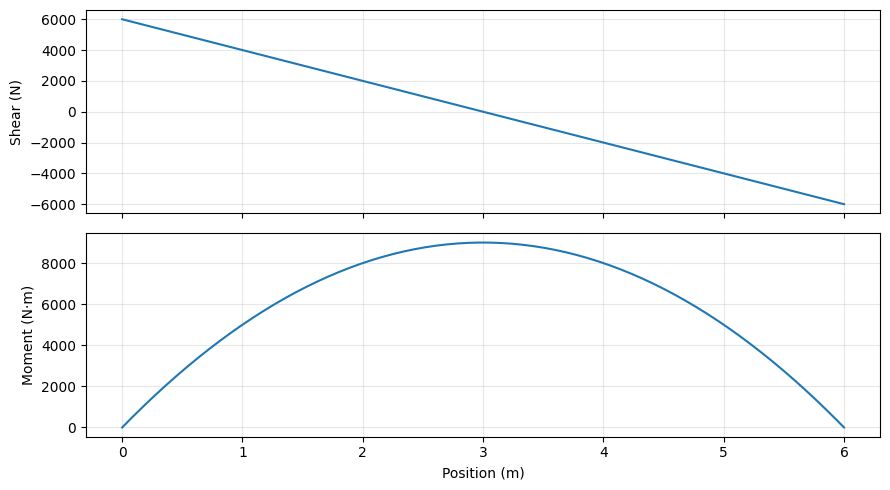

Outputs saved under: /mnt/data/benchart-v8-work/python-analytics/outputs


In [18]:
# Recreate the key static documentation images from the notebook's live data.
fig, axes = plt.subplots(2,1,figsize=(9,5),sharex=True)
axes[0].plot(beam_df.x_m,beam_df.shear_n); axes[0].set_ylabel("Shear (N)"); axes[0].grid(alpha=.3)
axes[1].plot(beam_df.x_m,beam_df.moment_nm); axes[1].set_ylabel("Moment (N·m)"); axes[1].set_xlabel("Position (m)"); axes[1].grid(alpha=.3)
plt.tight_layout(); fig.savefig(OUTPUT_DIR/"beam_lab_diagrams.png",dpi=160); plt.show()
bench.to_csv(OUTPUT_DIR/"cleaned_benchmarks.csv",index=False)
print("Outputs saved under:", OUTPUT_DIR.resolve())